# Step 4 — Frequent itemsets and association rules (A-priori vs. PCY)

*Code: `src/itemsets.py` (A-priori, PCY), `src/rules.py` (rules, comparison, null model), `src/benchmark.py` (runtime and memory). Tests: `tests/`. This notebook runs them and explains the choices.*

**Question.** Steps 2 and 3 split the same 7,947 Philadelphia users into **friend** communities and two kinds of **taste** communities. Here every user becomes a **basket** of the things they liked, and we ask which items are liked together (association rules) inside each community, and whether friend communities share rules the way taste communities do.

**Plan**
- **4.1** Baskets: restaurants liked, and categories of restaurants liked.
- **4.2** A-priori and PCY from scratch, and a check that they give identical results.
- **4.3** A-priori vs. PCY: runtime, memory, candidate pairs.
- **4.4** Association rules per community, for 3 community systems × 2 basket types.
- **4.5** Comparison of the rules across systems, against a null model, with the activity-period confounder.
- **4.6** Robustness over the 20 saved Louvain seeds.

## 0. Setup

All parameters are in this cell. Inputs are the files written by notebooks 01–03; nothing is recomputed from the raw Yelp JSON and no community is re-detected.

In [1]:
import sys, json, subprocess, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data" / "processed").exists())
sys.path.insert(0, str(ROOT / "src"))

import importlib, taste, itemsets as I, rules as R, benchmark as BM
for m in (taste, I, R, BM):
    importlib.reload(m)

# --- parameters -----------------------------------------------------------
SEED = 42
# baskets = step-3 liked sets, with exactly notebook 03's category filter
GENERIC_MAX_FRAC = 0.80
MAX_CATS_PER_BUSINESS = 20
MIN_BUSINESSES_PER_CATEGORY = 5
MIN_BASKET_ITEMS = 2              # step 1: skip baskets that cannot contain a pair

# mining (one support / confidence per basket type, the same for every community system)
MIN_SUPPORT = {"business": 0.01, "category": 0.15}
MIN_CONFIDENCE = {"business": 0.25, "category": 0.50}
MIN_LIFT = 1.0                    # keep only positively associated rules
MAX_K = 3                         # largest itemset size
MIN_COUNT_FLOOR = 5               # min_count = max(ceil(min_support * n), 5)
MIN_COMMUNITY_SIZE = 100          # mining transactions needed to mine a community

# comparison
LIFT_RATIO_MIN = 1.5              # "community-specific" rule: lift >= 1.5 x population lift
TAG_SHARE_MAX = 0.5               # category rule flagged as a Yelp-tag artefact above this share
N_SHUFFLES = 20                   # null model: random partitions with the same sizes

# A-priori vs PCY
N_BUCKETS = 100_003               # prime; ~4x the number of distinct category pairs seen
BUCKET_SWEEP = (1_009, 10_007, 100_003, 1_000_003)
TIMING_REPS = 5

PROC, RESULTS, FIGURES = ROOT / "data" / "processed", ROOT / "data" / "results", ROOT / "figures"
RESULTS.mkdir(parents=True, exist_ok=True); FIGURES.mkdir(exist_ok=True)
VERSIONS = ("business", "category")
print("project root:", ROOT)

project root: /Users/viktor/Desktop/masters/DTU_2026_27/1st_semester/Computational_Tools_for_Data_Science/project


## 4.1 Baskets

One basket per user. Items are either the **restaurants** the user liked or the **categories** of those restaurants. "Liked" is the stored `is_positive` column of step 1 (stars ≥ 3.5, i.e. 4 or 5 stars).

The baskets are exactly the liked sets of step 3: `taste.build_user_sets` with notebook 03's parameters. The category filter matters. Before it, *Food* is in 97% of the category baskets, *Nightlife* in 94% and *Bars* in 93%, and every rule would be built on them. The filter removes:
- categories liked by more than 80% of users;
- categories present in fewer than 5 restaurants;
- the one venue with more than 20 categories (Reading Terminal Market).

As in step 1, users with fewer than 2 items are not mining transactions, since they cannot contain a pair. They stay in the community files, and are simply absent when a community's baskets are collected.

In [2]:
reviews, businesses, users = taste.load_inputs(ROOT)
friend = pd.read_parquet(PROC / "philadelphia_pa_friend_communities.parquet").set_index("user_id")["friend_community"]
taste_c = pd.read_parquet(RESULTS / "taste_communities.parquet").set_index("user_id")
ALL_USERS = users["user_id"]

# every community file must describe the same population
for name, idx in [("friend", friend.index), ("taste", taste_c.index)]:
    assert set(idx) == set(ALL_USERS) and idx.is_unique, f"{name} population differs"
assert reviews.duplicated(["user_id", "business_id"]).sum() == 0, "duplicate user-restaurant pairs"
assert reviews[["user_id", "business_id"]].notna().all().all(), "missing ids"

USER_SETS, BASKETS = {}, {}
for v in VERSIONS:
    USER_SETS[v] = taste.build_user_sets(reviews, businesses, users, v,
                                         generic_max_frac=GENERIC_MAX_FRAC,
                                         max_cats_per_business=MAX_CATS_PER_BUSINESS,
                                         min_businesses_per_category=MIN_BUSINESSES_PER_CATEGORY)
    BASKETS[v] = I.baskets_from_user_sets(USER_SETS[v], ALL_USERS, MIN_BASKET_ITEMS)

cat_long, cat_info = taste.clean_business_categories(businesses, MAX_CATS_PER_BUSINESS, MIN_BUSINESSES_PER_CATEGORY)
basket_summary = pd.DataFrame([{
    "basket_type": v, "users": len(ALL_USERS), "users_empty": len(USER_SETS[v].empty_users),
    "users_excluded_lt2": len(BASKETS[v].excluded_users), "mining_transactions": len(BASKETS[v].sets),
    "unique_items": BASKETS[v].n_items,
    "size_median": float(np.median([len(s) for s in BASKETS[v].sets])),
    "size_mean": round(float(np.mean([len(s) for s in BASKETS[v].sets])), 1),
    "size_p90": float(np.percentile([len(s) for s in BASKETS[v].sets], 90)),
    "size_max": int(max(len(s) for s in BASKETS[v].sets))} for v in VERSIONS])
display(basket_summary)
print("generic categories dropped:", USER_SETS["category"].dropped_items)
print("venues dropped from the category version:", cat_info["venues_dropped"])
print("rare categories dropped:", cat_info["rare_categories_dropped"])

,basket_type,users,users_empty,users_excluded_lt2,mining_transactions,unique_items,size_median,size_mean,size_p90,size_max
0,business,7947,6,16,7931,5414,14.0,22.0,45.0,542
1,category,7947,6,9,7938,196,29.0,34.9,64.0,157


generic categories dropped: {'Food': 0.966, 'Nightlife': 0.939, 'Bars': 0.933, 'American (New)': 0.902, 'Breakfast & Brunch': 0.88, 'American (Traditional)': 0.832, 'Sandwiches': 0.828}
venues dropped from the category version: {'Reading Terminal Market': 35}
rare categories dropped: 170


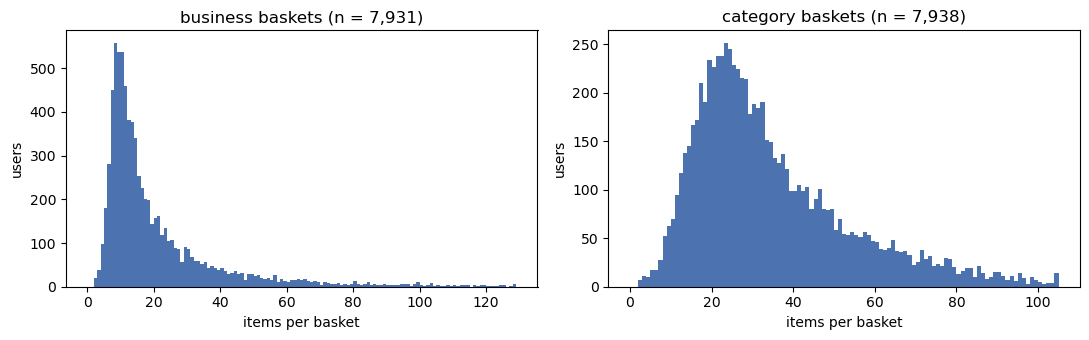

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, v in zip(axes, VERSIONS):
    sizes = [len(s) for s in BASKETS[v].sets]
    ax.hist(sizes, bins=np.arange(0, np.percentile(sizes, 99) + 2), color="#4c72b0")
    ax.set(title=f"{v} baskets (n = {len(sizes):,})", xlabel="items per basket", ylabel="users")
fig.tight_layout(); fig.savefig(FIGURES / "04_basket_sizes.png", dpi=150); plt.show()

In [4]:
# lookup tables: readable item names, and the business -> category table for the tag check
NAMES = {"business": businesses.set_index("business_id")["name"].reindex(BASKETS["business"].item_ids).to_numpy(),
         "category": BASKETS["category"].item_ids}
cat_index = pd.Series(np.arange(BASKETS["category"].n_items), index=BASKETS["category"].item_ids)
biz_rows = (cat_long[cat_long.category.isin(cat_index.index)]
            .assign(i=lambda d: cat_index.reindex(d.category).to_numpy())
            .groupby("business_id")["i"].apply(lambda s: np.sort(s.to_numpy())))
BIZ_INDEX = R.SupportIndex(list(biz_rows), BASKETS["category"].n_items)
POP = {v: R.SupportIndex(list(BASKETS[v].sets), BASKETS[v].n_items) for v in VERSIONS}
print(f"business-category table: {BIZ_INDEX.n:,} restaurants")

business-category table: 5,478 restaurants


> **What we found.**
> - **Population.** All three community files contain the same 7,947 users, and there are no duplicate or missing user–restaurant pairs.
> - **Mining transactions.** 7,931 users have a restaurant basket with ≥ 2 items; 16 are excluded, 6 of them with no liked restaurant at all (the 16 of notebook 01). The category version keeps 7,938 users, because a single liked restaurant can carry several categories.
> - **Restaurant baskets are long-tailed and sparse.** 5,414 restaurants; median 14 per basket, 90th percentile 45, maximum 542.
> - **Category baskets are dense.** 196 categories after the filter; median 29 per basket. The 7 generic categories removed are the ones in 83–97% of baskets (*Food*, *Nightlife*, *Bars*, *American (New)*, …).

## 4.2 A-priori and PCY

Both are written from scratch in `src/itemsets.py`. Items are integer indices and itemsets are sorted tuples, so outputs are deterministic and can be compared exactly.

**A-priori** (course version)
1. Pass 1 counts every item.
2. Pass 2 counts pairs of frequent items in a **triangular array** of m(m−1)/2 counters, m = number of frequent items.
3. Sizes k ≥ 3 join frequent (k−1)-itemsets that share their first k−2 items, prune every candidate with an infrequent (k−1)-subset, and count the survivors against the transactions.

**PCY**
1. Pass 1 also hashes every pair of every basket into `N_BUCKETS` counters. The pair is packed into a 64-bit key (i << 32 | j), scrambled with the fixed MurmurHash3 finaliser, and reduced modulo `N_BUCKETS`. Python's salted `hash()` is not used, so results are reproducible.
   - *A first version used a linear hash (A·i + B·j) mod P. With A = 1,000,003 equal to one of the bucket counts, the i term vanished and 19,900 pairs fell into about 200 buckets. Results stayed correct, because counting is exact, but the filter stopped working. A regression test now checks how evenly pairs are spread.*
2. The bucket counts become a **bitmap** (1 bit per bucket, `np.packbits`) and the counter array is freed.
3. Pass 2 counts, in a **hash table** (dict), only pairs of frequent items whose bucket is frequent.
4. Sizes k ≥ 3 use the same A-priori extension as above. PCY's own contribution is the pair stage, so the comparison below is about pairs.

A collision can only make a bucket *look* frequent (a false positive), never hide a frequent pair. The bitmap is a filter, and exact supports are always counted afterwards.

**Support threshold.** `min_count = max(ceil(min_support × n), 5)` for each collection of n transactions.

In [5]:
# unit tests: toy data with known answers, brute-force agreement, edge cases, forced collisions
out = subprocess.run([sys.executable, "-m", "pytest", "-q", str(ROOT / "tests")], capture_output=True, text=True, cwd=ROOT)
print(out.stdout.strip().splitlines()[-1])

37 passed in 0.54s


In [6]:
# the two algorithms on the full population: identical itemsets?
FULL = {}
for v in VERSIONS:
    T = list(BASKETS[v].sets)
    mc = I.min_support_count(MIN_SUPPORT[v], len(T), MIN_COUNT_FLOOR)
    a = I.apriori(T, BASKETS[v].n_items, mc, MAX_K)
    p = I.pcy(T, BASKETS[v].n_items, mc, N_BUCKETS, MAX_K)
    assert a.itemsets == p.itemsets, f"{v}: A-priori and PCY disagree"
    FULL[v] = a
    print(f"{v:<9} min_support {MIN_SUPPORT[v]:.0%} -> min_count {mc}: identical itemsets, by size {a.by_size()}")

business  min_support 1% -> min_count 80: identical itemsets, by size {1: 579, 2: 293, 3: 7}


category  min_support 15% -> min_count 1191: identical itemsets, by size {1: 80, 2: 1390, 3: 9568}


> **What we found.**
> - **Tests.** All 37 tests pass. They cover:
>   - toy data compared with a brute-force miner;
>   - support exactly at the threshold;
>   - empty and singleton baskets;
>   - no frequent singletons;
>   - forced collisions (1 bucket);
>   - the triangular-array indexing;
>   - the bitmap;
>   - the spread of the hash;
>   - the "no false negatives" invariant;
>   - the rule metrics on a hand-computed example.
> - **Identical results.** On the full population, A-priori and PCY return identical itemsets: 579 / 293 / 7 frequent itemsets of size 1 / 2 / 3 for restaurants (1% support, min_count 80), and 80 / 1,390 / 9,568 for categories (15%, min_count 1,191).
> - **Restaurant itemsets stop at size 3.** Even the most popular restaurants co-occur rarely.

## 4.3 A-priori vs. PCY: runtime, memory, candidate pairs

Both algorithms run on **identical** inputs: the same transactions, item encoding and min_count. The benchmark covers the **pair stage** (`max_k = 2`), where the two algorithms differ. The k ≥ 3 stage is the same code for both and would only add identical time and memory. The inputs are the full population and the largest eligible community of each system, for both basket types.

How each quantity is measured:
- **Runtime:** median of `TIMING_REPS` runs, timed per pass with `time.perf_counter` inside the algorithms. Loading, plotting and rule generation are excluded.
- **Memory:** one extra run under `tracemalloc` (peak Python allocation; NumPy arrays are included because NumPy allocates through Python's tracer). Next to it, the theoretical size of each structure: course convention of 4 bytes per counter and 12 bytes per hash-table entry.
- **Candidate pairs:** reported as separate, defined counts (table below). One ambiguous "candidates" number would hide the trade-off.

`benchmark.benchmark` stops with an error if the two algorithms ever disagree.

In [7]:
def largest_eligible(labels, v):
    for c in labels.value_counts().index:
        if len(BASKETS[v].subset(labels[labels == c].index)) >= MIN_COMMUNITY_SIZE:
            return c

SYSTEMS = {"friend": friend, "taste_business": taste_c["louvain_business"], "taste_category": taste_c["louvain_category"]}
bench_rows, cand_rows = [], []
for v in VERSIONS:
    colls = {"population": list(BASKETS[v].sets)}
    for s, lab in SYSTEMS.items():
        c = largest_eligible(lab, v)
        colls[f"{s} #{c}"] = BASKETS[v].subset(lab[lab == c].index)
    for name, T in colls.items():
        mc = I.min_support_count(MIN_SUPPORT[v], len(T), MIN_COUNT_FLOOR)
        rows, cand = BM.benchmark(T, BASKETS[v].n_items, mc, 2, N_BUCKETS, TIMING_REPS)
        bench_rows.append(rows.assign(basket_type=v, collection=name))
        cand_rows.append({"basket_type": v, "collection": name, "n_transactions": len(T), "min_count": mc, **cand})
BENCH = pd.concat(bench_rows, ignore_index=True)
CAND = pd.DataFrame(cand_rows)
cols = ["basket_type", "collection", "algorithm", "n_transactions", "min_count", "pass1_s", "pass2_pairs_s", "total_s", "total_s_min", "total_s_max", "peak_mem_mb"]
display(BENCH[cols].round(3))

,basket_type,collection,algorithm,n_transactions,min_count,pass1_s,pass2_pairs_s,total_s,total_s_min,total_s_max,peak_mem_mb
0,business,population,apriori,7931,80,0.001,0.118,0.120,0.118,0.127,2.601
1,business,population,pcy,7931,80,0.305,0.172,0.477,0.467,0.498,10.037
2,business,friend #0,apriori,2456,25,0.000,0.054,0.054,0.054,0.057,4.106
3,business,friend #0,pcy,2456,25,0.119,0.080,0.202,0.198,0.206,10.436
4,business,taste_business #0,apriori,1318,14,0.000,0.013,0.013,0.013,0.014,1.178
5,business,taste_business #0,pcy,1318,14,0.027,0.024,0.051,0.049,0.074,2.929
6,business,taste_category #0,apriori,1534,16,0.000,0.008,0.008,0.008,0.008,0.258
7,business,taste_category #0,pcy,1534,16,0.016,0.019,0.035,0.034,0.035,1.094
8,category,population,apriori,7938,1191,0.001,0.253,0.254,0.248,0.254,4.338
9,category,population,pcy,7938,1191,0.390,0.354,0.747,0.739,0.756,10.447


In [8]:
cand_cols = ["basket_type", "collection", "pairs_hashed_pass1", "nonempty_buckets", "frequent_buckets",
             "frequent_items", "apriori_candidate_pairs", "pcy_candidate_pairs", "removed_by_bitmap",
             "candidate_reduction_pct", "pcy_pairs_counted", "frequent_pairs"]
display(CAND[cand_cols].round(1))
mem_cols = ["basket_type", "collection", "triangular_bytes", "bucket_array_bytes", "bitmap_bytes", "hash_table_bytes_course"]
display((CAND[mem_cols].set_index(["basket_type", "collection"]) / 1024).round(1).add_suffix(" [KB]"))

,basket_type,collection,pairs_hashed_pass1,nonempty_buckets,frequent_buckets,frequent_items,apriori_candidate_pairs,pcy_candidate_pairs,removed_by_bitmap,candidate_reduction_pct,pcy_pairs_counted,frequent_pairs
0,business,population,4521167,100003,5463,579,167331,18634,148697,88.9,18405,293
1,business,friend #0,1895174,100001,21094,717,256686,82289,174397,67.9,72048,964
2,business,taste_business #0,279864,86283,906,429,91806,1990,89816,97.8,1565,489
3,business,taste_category #0,79595,51070,2,180,16110,3,16107,100.0,2,1
4,category,population,6393958,17306,1455,80,3160,1505,1655,52.4,1505,1390
5,category,friend #0,2445929,17190,1987,86,3655,2041,1614,44.2,2041,1919
6,category,taste_business #0,920100,15586,1327,74,2701,1362,1339,49.6,1362,1294
7,category,taste_category #0,316681,11964,211,47,1081,215,866,80.1,215,204


triangular_bytes [KB]  bucket_array_bytes [KB]  \
basket_type collection                                                          
business    population                         653.6                    390.6   
            friend #0                         1002.7                    390.6   
            taste_business #0                  358.6                    390.6   
            taste_category #0                   62.9                    390.6   
category    population                          12.3                    390.6   
            friend #0                           14.3                    390.6   
            taste_business #0                   10.6                    390.6   
            taste_category #0                    4.2                    390.6   

                               bitmap_bytes [KB]  hash_table_bytes_course [KB]  
basket_type collection                                                          
business    population                      12.2                         215.7  
            friend #0                       12.2                         844.3  
            taste_business #0               12.2                          18.3  
            taste_category #0               12.2                           0.0  
category    population                      12.2                          17.6  
            friend #0                       12.2                          23.9  
            taste_business #0               12.2                          16.0  
            taste_category #0               12.2                           2.5

**What the candidate-pair columns mean**

| Column | Definition |
|---|---|
| `pairs_hashed_pass1` | pair occurrences hashed by PCY in pass 1 (every pair of every basket) |
| `nonempty_buckets`, `frequent_buckets` | buckets with count > 0, and with count ≥ min_count |
| `apriori_candidate_pairs` | all pairs of frequent items, m(m−1)/2: what A-priori allocates and counts |
| `pcy_candidate_pairs` | pairs of frequent items whose bucket is frequent: PCY's candidate set |
| `removed_by_bitmap` | the difference; `candidate_reduction_pct` is it as a percentage |
| `pcy_pairs_counted` | candidates that actually occur in a basket, i.e. the hash-table entries |
| `frequent_pairs` | pairs with support ≥ min_count (identical for both algorithms) |

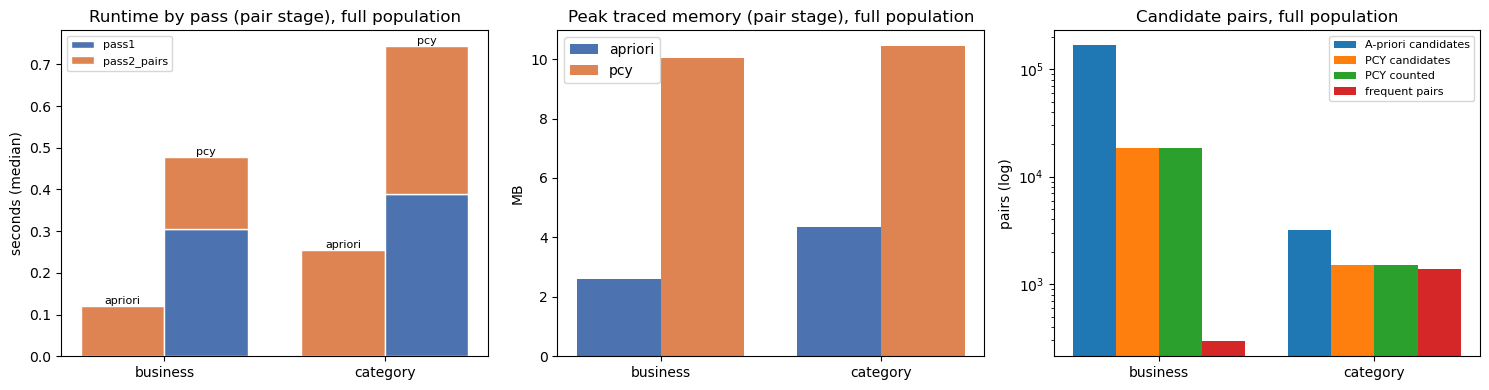

In [9]:
pop_b = BENCH[BENCH.collection == "population"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
w = 0.38
for k, v in enumerate(VERSIONS):
    for j, algo in enumerate(("apriori", "pcy")):
        r = pop_b[(pop_b.basket_type == v) & (pop_b.algorithm == algo)].iloc[0]
        bottom = 0
        for part, col in [("pass1_s", "#4c72b0"), ("pass2_pairs_s", "#dd8452")]:
            axes[0].bar(k + (j - .5) * w, r[part], w, bottom=bottom, color=col,
                        label=part.replace("_s", "") if (k, j) == (0, 0) else None, edgecolor="white")
            bottom += r[part]
        axes[0].text(k + (j - .5) * w, bottom, algo, ha="center", va="bottom", fontsize=8)
        axes[1].bar(k + (j - .5) * w, r.peak_mem_mb, w, color=["#4c72b0", "#dd8452"][j], label=algo if k == 0 else None)
axes[0].set(xticks=range(2), xticklabels=VERSIONS, ylabel="seconds (median)", title="Runtime by pass (pair stage), full population"); axes[0].legend(fontsize=8)
axes[1].set(xticks=range(2), xticklabels=VERSIONS, ylabel="MB", title="Peak traced memory (pair stage), full population"); axes[1].legend()
cp = CAND[CAND.collection == "population"].set_index("basket_type")
x = np.arange(2)
for j, (col, lab) in enumerate([("apriori_candidate_pairs", "A-priori candidates"), ("pcy_candidate_pairs", "PCY candidates"),
                                ("pcy_pairs_counted", "PCY counted"), ("frequent_pairs", "frequent pairs")]):
    axes[2].bar(x + (j - 1.5) * 0.2, cp.loc[list(VERSIONS), col], 0.2, label=lab)
axes[2].set(xticks=x, xticklabels=VERSIONS, yscale="log", ylabel="pairs (log)", title="Candidate pairs, full population"); axes[2].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIGURES / "04_apriori_vs_pcy.png", dpi=150); plt.show()

,n_buckets,frequent_buckets,share_frequent_buckets,pcy_candidate_pairs,candidate_reduction_pct,pcy_pairs_counted,bucket_array_kb,bitmap_kb,hash_table_kb_course,peak_mem_mb,pass1_s,pass2_s,basket_type
0,1009,1009,1.000,167331,0.000,163030,3.941,0.124,1910.508,15.735,0.306,0.277,business
1,10007,10007,1.000,167331,0.000,163030,39.090,1.222,1910.508,15.736,0.297,0.265,business
2,100003,5463,0.055,18634,88.864,18405,390.637,12.208,215.684,10.037,0.300,0.167,business
3,1000003,387,0.000,480,99.713,477,3906.262,122.071,5.590,13.471,0.327,0.139,business
4,1009,1002,0.993,3159,0.032,3159,3.941,0.124,37.020,14.556,0.394,0.421,category
5,10007,1828,0.183,2204,30.253,2204,39.090,1.222,25.828,11.975,0.391,0.382,category
6,100003,1455,0.015,1505,52.373,1505,390.637,12.208,17.637,10.447,0.410,0.354,category
7,1000003,1398,0.001,1403,55.601,1403,3906.262,122.071,16.441,13.880,0.413,0.385,category


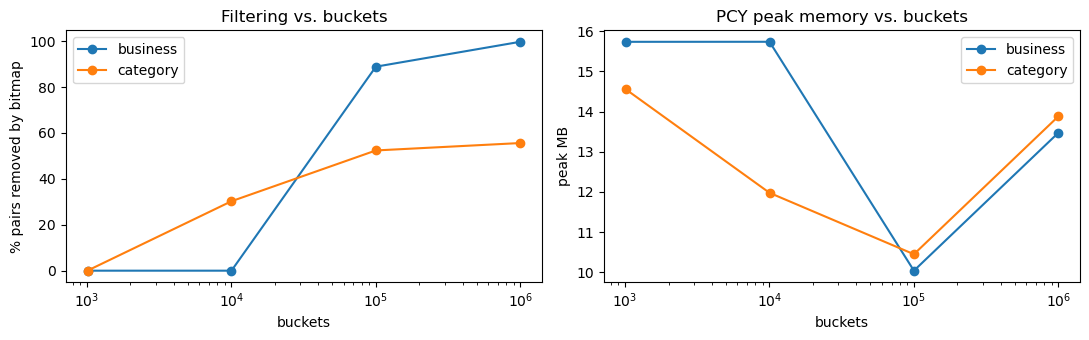

In [10]:
# effect of the number of buckets (pairs only, full population)
SWEEP = pd.concat([BM.bucket_sweep(list(BASKETS[v].sets), BASKETS[v].n_items,
                                   I.min_support_count(MIN_SUPPORT[v], len(BASKETS[v].sets), MIN_COUNT_FLOOR),
                                   BUCKET_SWEEP).assign(basket_type=v) for v in VERSIONS], ignore_index=True)
display(SWEEP.round(3))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for v in VERSIONS:
    s = SWEEP[SWEEP.basket_type == v]
    axes[0].plot(s.n_buckets, s.candidate_reduction_pct, "o-", label=v)
    axes[1].plot(s.n_buckets, s.peak_mem_mb, "o-", label=v)
axes[0].set(xscale="log", xlabel="buckets", ylabel="% pairs removed by bitmap", title="Filtering vs. buckets")
axes[1].set(xscale="log", xlabel="buckets", ylabel="peak MB", title="PCY peak memory vs. buckets")
for a in axes: a.legend()
fig.tight_layout(); fig.savefig(FIGURES / "04_pcy_bucket_sweep.png", dpi=150); plt.show()

> **What we found** (pair stage, median of 5 runs).
>
> **Runtime: A-priori is faster everywhere, 3–5×.**
> - PCY's pass 1 hashes **every** pair of every basket: 4.5 M pair occurrences for restaurants, 6.4 M for categories. A-priori's pass 1 is a single count of items.
> - On the full population PCY's pass 1 alone takes 0.30 s (restaurants) and 0.40 s (categories), longer than A-priori's whole pair stage (0.12 s and 0.25 s).
> - Pass 2 is also slightly slower for PCY: a Python dict versus a NumPy array.
>
> **Candidate pairs: the bitmap filters well when frequent pairs are rare.**
> - Restaurants: 89% of the 167,331 pairs of frequent restaurants are removed, leaving 18,634 candidates for 293 frequent pairs (98–100% in the taste communities).
> - Categories: about 52% are removed. Of the 3,160 pairs of frequent categories, 1,390 *are* frequent, so no bitmap could remove more than 56%.
>
> **Memory, course model (4 bytes per counter, 12 per hash entry).**
> - The course's "1/3 rule": PCY saves memory in pass 2 only if it counts fewer than ⅓ of the pairs A-priori would count. Its table spends 12 bytes per pair against 4 for a triangular counter.
> - Restaurants, full population: rule met. PCY counts 18,405 pairs against 167,331 for A-priori. Pass 2 needs 12 KB (bitmap) + 216 KB (table) against a 654 KB triangular array, about 3× less.
> - Largest friend community: rule met, but only just. 72,048 of 256,686 pairs counted; 856 KB against 1,003 KB.
> - Categories: rule fails. With only 80 frequent categories, the triangular array is 12 KB, and PCY's table (18 KB) plus bitmap (12 KB) is larger. PCY's 391 KB bucket array in pass 1 is also far more than A-priori ever needs.
>
> **Memory, measured (tracemalloc).**
> - A-priori's peak is lower in every case, e.g. 2.6 MB vs. 10.0 MB for restaurants on the full population.
> - In Python, the peak comes from the per-chunk arrays of hashed pairs in pass 1, not from the counters. A-priori never builds pairs of infrequent items. The course argument about main memory (the bucket array fills memory that A-priori leaves idle in pass 1) assumes a memory-bound implementation, which this is not at this data size.
>
> **Number of buckets.**
> - Too few buckets make every bucket frequent and the filter useless: 1,009 and 10,007 buckets remove 0% of restaurant pairs.
> - 100,003 buckets remove 89%, and 1,000,003 remove 99.7% (480 candidates for 293 frequent pairs). But the bucket array then grows to 3.9 MB, against 654 KB for A-priori's triangular array.
> - For categories, the filter levels off at about 56%, the limit set by the truly frequent pairs.
>
> **Conclusion.** PCY pays off where it was designed to: many frequent items and few frequent pairs (restaurant baskets), with enough buckets. On dense category baskets, and at this data size in Python, A-priori is faster and smaller. We do **not** claim that PCY is faster.

## 4.4 Association rules per community

For a rule X → Y (X, Y non-empty and disjoint, X ∪ Y frequent):

$$\text{support} = \frac{s(X\cup Y)}{n},\qquad \text{confidence} = \frac{s(X\cup Y)}{s(X)},\qquad \text{lift} = \frac{\text{confidence}}{s(Y)/n}$$

All of these use the exact counts from mining. A rule describes **co-occurrence among liked items**, not causation.

**Two extra columns per rule**
- **`lift_pop`, `lift_ratio`**: the same rule's lift on the whole population, and lift in the community ÷ lift in the population. A large community with the same support fraction mostly reproduces global rules. A rule is **community-specific** when `lift_ratio ≥ 1.5`.
- **`same_business_share`** (category rules only): the share of restaurants tagged with all of X that are also tagged with all of Y. A high share means the rule restates how Yelp tags a single restaurant (*Sushi Bars → Japanese*), not two tastes of one user. Rules above 0.5 are flagged.

**Thresholds** (setup cell): one support and one confidence per basket type, the same for all three community systems.
- **Restaurant baskets are sparse.** The most-liked restaurant is in 15% of baskets. At 1% support the population has 293 frequent pairs; at 3% it has 1.
- **Category baskets are dense** (median 29 items after filtering). At 10% support the population already has 25k frequent triples.
- Confidence differs too: restaurant rules have a median confidence of about 0.2, category rules about 0.5.
- `MIN_COMMUNITY_SIZE = 100` mining transactions. Smaller communities, including the singleton communities of step 3's isolated users, are listed as excluded.

**Same algorithm everywhere.** Communities are mined with A-priori. Section 4.2 showed that PCY returns the same itemsets.

In [11]:
SYSTEMS_ALL = {**SYSTEMS, "period": taste_c["period"].astype(str)}   # period: confounder check (4.5)

def params(v, max_k=MAX_K):
    return R.MiningParams(MIN_SUPPORT[v], MIN_CONFIDENCE[v], MIN_LIFT, max_k, MIN_COUNT_FLOOR,
                          MIN_COMMUNITY_SIZE, LIFT_RATIO_MIN)

SUMMARY, RULES = {}, {}
t0 = time.perf_counter()
for v in VERSIONS:
    for s, lab in SYSTEMS_ALL.items():
        SUMMARY[s, v], RULES[s, v] = R.mine_partition(BASKETS[v], lab, params(v), POP[v],
                                                      BIZ_INDEX if v == "category" else None)
print(f"mined 4 systems x 2 basket types in {time.perf_counter() - t0:.0f} s")

comm = pd.concat([d.assign(community_system=s, basket_type=v) for (s, v), d in SUMMARY.items()], ignore_index=True)
excl = (comm.groupby(["community_system", "basket_type"])
            .agg(communities=("community_id", "size"), eligible=("eligible", "sum"),
                 users_in_eligible=("n_assigned", lambda x: int(x[comm.loc[x.index, "eligible"]].sum())))
            .assign(excluded=lambda d: d.communities - d.eligible))
display(excl)

mined 4 systems x 2 basket types in 36 s


communities  eligible  users_in_eligible  \
community_system basket_type                                             
friend           business              51         7               7532   
                 category              51         7               7532   
period           business               4         4               7947   
                 category               4         4               7947   
taste_business   business              17        11               7941   
                 category              17        11               7941   
taste_category   business              17         8               7885   
                 category              17         8               7885   

                              excluded  
community_system basket_type            
friend           business           44  
                 category           44  
period           business            0  
                 category            0  
taste_business   business            6  
                 category            6  
taste_category   business            9  
                 category            9

In [12]:
show = ["community_system", "basket_type", "community_id", "n_assigned", "n_transactions", "n_items", "min_count",
        "frequent_k1", "frequent_k2", "frequent_k3", "rules_before_filter", "rules", "rules_specific"]
display(comm[comm.eligible & (comm.community_system != "period")][show])

,community_system,basket_type,community_id,n_assigned,n_transactions,n_items,min_count,frequent_k1,frequent_k2,frequent_k3,rules_before_filter,rules,rules_specific
0,friend,business,0,2460,2456,4372.0,25.0,717.0,964.0,124.0,2672.0,894.0,0.0
1,friend,business,1,1667,1664,3606.0,17.0,532.0,345.0,0.0,690.0,136.0,7.0
2,friend,business,2,1607,1606,3944.0,17.0,694.0,1997.0,300.0,5794.0,2193.0,64.0
3,friend,business,3,818,818,2623.0,9.0,500.0,744.0,86.0,2004.0,732.0,115.0
4,friend,business,4,661,661,1932.0,7.0,336.0,216.0,18.0,540.0,179.0,17.0
5,friend,business,5,196,195,1374.0,5.0,125.0,5.0,0.0,10.0,8.0,4.0
6,friend,business,6,123,122,1092.0,5.0,45.0,0.0,0.0,0.0,0.0,0.0
51,taste_business,business,0,1319,1318,3054.0,14.0,429.0,489.0,67.0,1380.0,413.0,1.0
52,taste_business,business,1,1198,1198,4440.0,12.0,1443.0,29380.0,41199.0,305954.0,114483.0,2.0
53,taste_business,business,2,1059,1057,3077.0,11.0,261.0,151.0,19.0,416.0,152.0,1.0


In [13]:
def readable(rules, v):
    n = NAMES[v]
    fmt = lambda t: " + ".join(str(n[i]) for i in t)
    return rules.assign(rule=[f"{fmt(a)} → {fmt(c)}" for a, c in zip(rules.antecedent, rules.consequent)])

def top_rules(s, v, k=3, specific=True):
    r = RULES[s, v]
    r = r[r.specific] if specific else r
    if v == "category":
        r = r[~(r.same_business_share >= TAG_SHARE_MAX)]
    r = r.sort_values(["community_id", "lift_ratio", "lift"], ascending=[True, False, False]).groupby("community_id").head(k)
    cols = ["community_id", "rule", "support", "confidence", "lift", "lift_pop", "lift_ratio"]
    return readable(r, v)[cols].round(3)

for v in VERSIONS:
    for s in SYSTEMS:
        print(f"\n=== {s} x {v}: top community-specific rules (max 3 per community{', tag rules removed' if v == 'category' else ''})")
        display(top_rules(s, v))


=== friend x business: top community-specific rules (max 3 per community)


,community_id,rule,support,confidence,lift,lift_pop,lift_ratio
953,1,Sang Kee Peking Duck House → Amada,0.010,0.309,3.475,1.728,2.012
993,1,North Bowl → Reading Terminal Market,0.014,0.291,2.850,1.606,1.774
941,1,New Delhi Indian Restaurant → Reading Terminal...,0.010,0.386,3.782,2.189,1.727
1124,2,Bud & Marilyn's → Dizengoff,0.011,0.288,7.230,3.263,2.216
1125,2,Dizengoff → Bud & Marilyn's,0.011,0.266,7.230,3.263,2.216
1257,2,Jong Ka Jib → Cafe La Maude,0.011,0.383,6.030,2.951,2.044
3285,3,Tria Cafe Wash West → Little Nonna's,0.012,0.385,7.317,2.474,2.958
3296,3,Nan Zhou Hand Drawn Noodle House + Oyster Hous...,0.012,0.500,7.175,2.661,2.696
3572,3,Sabrina's Café → Reading Terminal Market,0.011,0.391,3.679,1.424,2.584
3957,4,Tom's Dim Sum → Terakawa Ramen,0.011,0.700,15.955,4.720,3.380



=== taste_business x business: top community-specific rules (max 3 per community)


,community_id,rule,support,confidence,lift,lift_pop,lift_ratio
37,0,Pat's King of Steaks → Zahav,0.012,0.593,2.675,1.233,2.169
37765,1,Lucky's Last Chance → Fogo de Chao,0.010,0.333,2.894,1.741,1.662
52002,1,Lloyd Whiskey Bar → Reading Terminal Market,0.012,0.636,2.584,1.611,1.604
114902,2,Barbuzzo → Monk's Cafe,0.012,0.295,4.056,2.230,1.819
115078,4,Steve's Prince of Steaks → Reading Terminal Ma...,0.013,0.293,4.419,1.757,2.515
115093,4,Zahav → Nan Zhou Hand Drawn Noodle House,0.014,0.433,2.982,1.780,1.676
115103,4,The Dandelion → Nan Zhou Hand Drawn Noodle House,0.012,0.379,2.611,1.650,1.583
115206,5,Dalessandro’s Steaks & Hoagies → Standard Tap,0.011,0.400,4.333,1.631,2.657
115143,5,Stock → Zahav,0.011,0.320,6.729,2.768,2.431
115182,5,Nan Zhou Hand Drawn Noodle House → Cafe La Maude,0.013,0.692,4.901,2.129,2.302



=== taste_category x business: top community-specific rules (max 3 per community)


,community_id,rule,support,confidence,lift,lift_pop,lift_ratio
1,1,Tommy DiNic's → Beiler's Bakery,0.013,0.293,6.923,3.783,1.830
0,1,Beiler's Bakery → Tommy DiNic's,0.013,0.309,6.923,3.783,1.830
6,1,John's Roast Pork → Reading Terminal Market,0.018,0.377,2.915,1.765,1.652
29,2,Morimoto → Reading Terminal Market,0.010,0.394,2.793,1.565,1.785
54,3,Osteria → Zahav,0.010,0.545,4.146,2.692,1.540
147110,5,Gran Caffe L'Aquila → Reading Terminal Market,0.012,0.357,2.801,1.538,1.821
147075,5,Estia → Max Brenner - Philadelphia,0.011,0.250,4.548,2.569,1.770
147072,5,Hawthornes Biercafé → Little Fish,0.011,0.250,5.625,3.241,1.736
147357,6,Vernick Food & Drink → HipCityVeg,0.014,0.417,8.472,2.359,3.591
147358,6,HipCityVeg → Vernick Food & Drink,0.014,0.278,8.472,2.359,3.591


... (2 outputs left out)


=== taste_business x category: top community-specific rules (max 3 per community, tag rules removed)


,community_id,rule,support,confidence,lift,lift_pop,lift_ratio
509687,4,Beer → Event Planning & Services + Wine & Spirits,0.175,0.524,2.997,1.813,1.653
509688,4,Wine & Spirits → Beer + Event Planning & Services,0.175,0.524,2.997,1.813,1.653
509689,4,Beer → Vegetarian + Wine & Spirits,0.170,0.508,2.997,1.813,1.653
527685,6,Pizza + Sushi Bars → Japanese,0.169,0.867,2.607,1.716,1.519
527686,6,Japanese → Pizza + Sushi Bars,0.169,0.509,2.607,1.716,1.519
527684,6,Sushi Bars + Vegetarian → Japanese,0.157,0.868,2.610,1.726,1.512
548458,8,Specialty Food + Vegetarian → Ethnic Food,0.164,0.626,2.887,1.790,1.613
548459,8,Ethnic Food → Specialty Food + Vegetarian,0.164,0.756,2.887,1.790,1.613
548462,8,Ethnic Food → Chinese + Specialty Food,0.156,0.720,2.720,1.783,1.525
564006,9,Caterers → Event Planning & Services + Vegetarian,0.175,0.867,3.514,1.948,1.804



=== taste_category x category: top community-specific rules (max 3 per community, tag rules removed)


,community_id,rule,support,confidence,lift,lift_pop,lift_ratio
4,0,Beer → Japanese + Wine & Spirits,0.160,0.746,4.650,1.813,2.565
5,0,Wine & Spirits → Beer + Japanese,0.160,0.746,4.650,1.813,2.565
13,0,Specialty Food → Ethnic Food,0.192,0.567,2.948,1.573,1.874
511,1,Ethnic Food → Specialty Food + Vegetarian,0.167,0.753,3.044,1.790,1.701
512,1,Specialty Food + Vegetarian → Ethnic Food,0.167,0.674,3.044,1.790,1.701
642256,6,Japanese → Sushi Bars + Wine Bars,0.189,0.590,2.767,1.741,1.589
642257,6,Sushi Bars + Wine Bars → Japanese,0.189,0.885,2.767,1.741,1.589
642268,6,Japanese → Salad + Sushi Bars,0.189,0.590,2.732,1.730,1.579


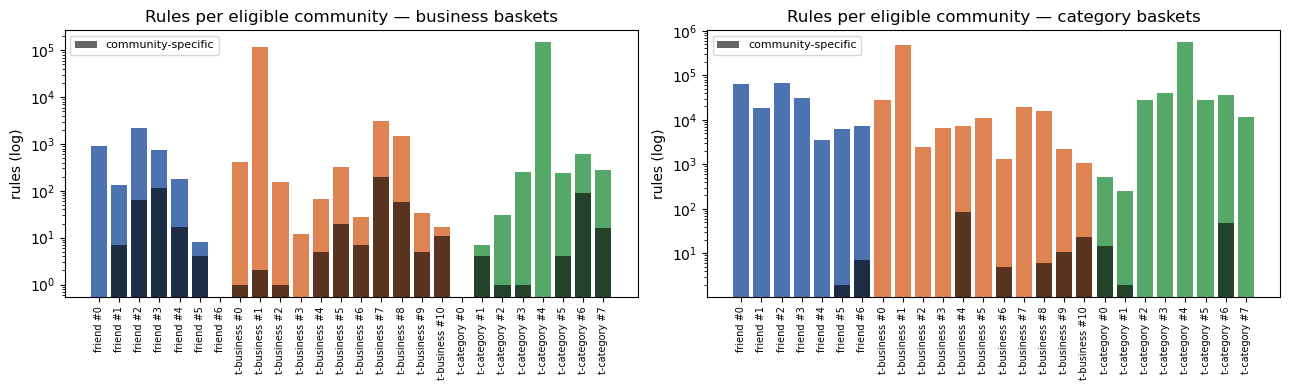

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, v in zip(axes, VERSIONS):
    d = comm[comm.eligible & (comm.basket_type == v) & (comm.community_system != "period")]
    lab = d.community_system.str.replace("taste_", "t-") + " #" + d.community_id.astype(str)
    colors = d.community_system.map({"friend": "#4c72b0", "taste_business": "#dd8452", "taste_category": "#55a868"})
    ax.bar(range(len(d)), d.rules, color=colors)
    ax.bar(range(len(d)), d.rules_specific, color="black", alpha=.6, label="community-specific")
    ax.set(yscale="log", title=f"Rules per eligible community — {v} baskets", ylabel="rules (log)")
    ax.set_xticks(range(len(d))); ax.set_xticklabels(lab, rotation=90, fontsize=7); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIGURES / "04_rules_per_community.png", dpi=150); plt.show()

In [15]:
# same-business tag artefacts among category rules
tag = pd.DataFrame([{"community_system": s, "rules": len(RULES[s, "category"]),
                     "tag_flagged": int((RULES[s, "category"].same_business_share >= TAG_SHARE_MAX).sum()),
                     "pair_rules": len(R.pair_rules(RULES[s, "category"])),
                     "pair_tag_flagged": int((R.pair_rules(RULES[s, "category"]).same_business_share >= TAG_SHARE_MAX).sum())}
                    for s in SYSTEMS]).assign(share_flagged=lambda d: (d.tag_flagged / d.rules).round(3))
display(tag)
ex = readable(R.pair_rules(RULES["friend", "category"]), "category").drop_duplicates("rule")
display(ex.sort_values("same_business_share", ascending=False)[["rule", "same_business_share", "lift"]].head(8).round(2))

,community_system,rules,tag_flagged,pair_rules,pair_tag_flagged,share_flagged
0,friend,196274,6709,9855,122,0.034
1,taste_business,567226,11084,15319,197,0.020
2,taste_category,689898,12609,15437,172,0.018


,rule,same_business_share,lift
0,Music Venues → Arts & Entertainment,1.0,3.16
1574,Ramen → Japanese,1.0,1.66
1098,Wine & Spirits → Beer,1.0,1.70
968,Beer → Wine & Spirits,1.0,1.70
1679,Caterers → Event Planning & Services,1.0,1.65
1761,Venues & Event Spaces → Event Planning & Services,1.0,1.65
159691,Cantonese → Chinese,1.0,1.34
455,Falafel → Mediterranean,1.0,1.79


> **What we found.**
> - **Eligibility.** With ≥ 100 mining transactions, 7 of 51 friend communities, 11 of 17 restaurant-taste and 8 of 17 category-taste communities are mined. They hold 95%, 99.9% and 99% of the users. The excluded communities are the small friend groups and the singleton communities of step 3's isolated users.
> - **Rule counts are uneven, by construction.** One restaurant-taste community (#1) and one category-taste community (#4) are made of **heavy reviewers**, with median baskets of about 50 items against about 12 elsewhere. With a fixed support fraction almost every triple there is frequent, and those two communities alone produce most of the rules. This is why section 4.5 compares **pair rules**.
> - **Restaurant rules** describe destinations liked together: *Reading Terminal Market*, *Zahav*, *Dizengoff* and similar. In taste communities the specific rules are often local clusters, e.g. *Mike's BBQ ↔ South Philly Barbacoa* (lift 30 inside the community vs. 9.6 in the population) or *The Dandelion ↔ HipCityVeg*.
> - **Category rules** read as cuisines liked together (*Vegetarian → Vegan*, *Middle Eastern → Mediterranean*, *French → Wine Bars*), and these appear in **all 7** friend communities.
> - **Tag artefacts are few but real.** 2–3% of category rules have `same_business_share ≥ 0.5`. Pairs such as *Ramen → Japanese*, *Cantonese → Chinese* or *Falafel → Mediterranean* have a share of 1.0: every restaurant with the first tag also has the second. They are flagged and removed from the comparison.

## 4.5 Comparing rules across community systems

**Pair rules only.** Comparisons use rules with one item on each side.
- Rules from triples grow combinatorially in the communities of **heavy reviewers**. One restaurant-taste and one category-taste community have median baskets of about 50 items, against about 12 elsewhere. With a fixed support fraction almost every triple there is frequent, and those few communities would dominate every overlap number.
- Triple rules are still mined and saved (4.4).
- The direction of a rule is kept: A → B ≠ B → A.

**Measures, per system and basket type**
- `median_lift_ratio`, `share_lift_ratio_lt1`: does the partition **absorb** the population's associations? If a partition puts together users who like the same things, an association across the population is partly explained by community membership, so inside a community the lift drops towards 1 (`lift_ratio` < 1).
- `rules_specific`: rules with `lift_ratio ≥ 1.5`.
- `all_/specific_mean_pairwise_jaccard`: average Jaccard between the rule sets of two communities (low = different rules).
- `all_/specific_share_unique`: share of rules found in only one community.
- `jaccard_vs_*`: Jaccard between the union of a system's specific rules and another system's.

**Null model.** Each number is compared with `N_SHUFFLES` random partitions that have exactly the same community sizes (labels shuffled over users), as steps 2 and 3 did for modularity.

**The taste communities are a reference, not a finding.** They were built from these same liked sets, so they are *expected* to differ from random. The informative comparison is **friend vs. null, measured against how far taste goes**.

**Activity-period confounder.** Step 2 found that friend communities follow the users' period of activity (NMI ≈ 0.22). We therefore add the 4 period bins of `taste_communities.parquet` as a fourth "partition". If friend-specific restaurant rules are mostly period rules, they overlap with the period-specific rules.

Category rules flagged as Yelp-tag artefacts are excluded from the comparison.

In [16]:
REAL, NULL = [], []
t0 = time.perf_counter()
for v in VERSIONS:
    tag_cut = TAG_SHARE_MAX if v == "category" else None
    spec = {s: R.union(R.rule_sets(R.pair_rules(RULES[s, v]), specific_only=True, exclude_tag=tag_cut)) for s in SYSTEMS_ALL}
    for s, lab in SYSTEMS_ALL.items():
        ref = {o: spec[o] for o in SYSTEMS_ALL if o != s}
        REAL.append({"basket_type": v, "community_system": s, **R.partition_measures(RULES[s, v], tag_cut, ref)})
        nm = R.null_model(BASKETS[v], lab, params(v, max_k=2), POP[v], N_SHUFFLES, SEED,
                          BIZ_INDEX if v == "category" else None, ref, tag_cut)
        NULL.append(nm.assign(basket_type=v, community_system=s))
REAL, NULL = pd.DataFrame(REAL), pd.concat(NULL, ignore_index=True)
print(f"null model: {N_SHUFFLES} shuffles x 4 systems x 2 basket types in {time.perf_counter() - t0:.0f} s")

null model: 20 shuffles x 4 systems x 2 basket types in 44 s


In [17]:
MEASURES = ["pair_rules", "median_lift_ratio", "share_lift_ratio_lt1", "rules_specific",
            "all_mean_pairwise_jaccard", "all_share_unique", "specific_share_unique"]

def vs_null(measures):
    rows = []
    for (v, s), g in NULL.groupby(["basket_type", "community_system"]):
        real = REAL[(REAL.basket_type == v) & (REAL.community_system == s)].iloc[0]
        for m in measures:
            if m not in g: continue
            mu, sd = g[m].mean(), g[m].std()
            rows.append({"basket_type": v, "community_system": s, "measure": m, "real": real[m],
                         "null_mean": mu, "null_sd": sd, "z": (real[m] - mu) / sd if sd > 0 else np.nan})
    return pd.DataFrame(rows)

CMP = vs_null(MEASURES)
order = list(SYSTEMS_ALL)
for v in VERSIONS:
    print(f"\n=== {v} baskets: real partition vs. {N_SHUFFLES} same-size random partitions")
    t = CMP[CMP.basket_type == v].pivot(index="measure", columns="community_system", values=["real", "null_mean", "z"])
    display(t.reindex(MEASURES).swaplevel(axis=1).reindex(columns=order, level=0).round(3))


=== business baskets: real partition vs. 20 same-size random partitions


community_system             friend                   taste_business  \
                               real null_mean       z           real   
measure                                                                
pair_rules                 2534.000  1615.300   4.190      14279.000   
median_lift_ratio             1.030     1.268  -5.049          0.595   
share_lift_ratio_lt1          0.445     0.113  20.795          0.952   
rules_specific              151.000   466.950  -2.040        240.000   
all_mean_pairwise_jaccard     0.033     0.100  -7.646          0.002   
all_share_unique              0.824     0.711   3.439          0.966   
specific_share_unique         1.000     0.985   1.875          1.000   

community_system                             taste_category                    \
                          null_mean        z           real null_mean       z   
measure                                                                         
pair_rules                 3814.950   37.692      15401.000  2608.450  42.339   
median_lift_ratio             1.433  -26.230          0.609     1.339 -18.021   
share_lift_ratio_lt1          0.072  122.082          0.976     0.095  86.359   
rules_specific             1702.500   -6.878        106.000   935.050  -3.577   
all_mean_pairwise_jaccard     0.098  -17.235          0.019     0.135 -19.396   
all_share_unique              0.705   13.461          0.963     0.690  10.771   
specific_share_unique         0.934   12.081          1.000     0.966   3.508   

community_system             period                    
                               real null_mean       z  
measure                                                
pair_rules                 1437.000   808.450  12.286  
median_lift_ratio             1.039     1.134 -10.785  
share_lift_ratio_lt1          0.440     0.173  28.369  
rules_specific               41.000    67.000  -1.732  
all_mean_pairwise_jaccard     0.065     0.222 -19.134  
all_share_unique              0.834     0.655   7.392  
specific_share_unique         1.000     0.999   0.224


=== category baskets: real partition vs. 20 same-size random partitions


community_system             friend                    taste_business  \
                               real  null_mean       z           real   
measure                                                                 
pair_rules                 9733.000  12066.750  -7.256      15122.000   
median_lift_ratio             0.993      1.002  -6.927          0.889   
share_lift_ratio_lt1          0.556      0.465   4.775          0.858   
rules_specific                0.000      0.950  -0.700          3.000   
all_mean_pairwise_jaccard     0.431      0.797 -37.662          0.259   
all_share_unique              0.252      0.166   2.578          0.677   
specific_share_unique           NaN      1.000     NaN          1.000   

community_system                              taste_category             \
                           null_mean        z           real  null_mean   
measure                                                                   
pair_rules                 18830.000  -11.102      15265.000  13632.500   
median_lift_ratio              1.003 -160.677          0.845      1.002   
share_lift_ratio_lt1           0.468   47.607          0.954      0.473   
rules_specific                 0.000      NaN          1.000      0.000   
all_mean_pairwise_jaccard      0.806  -46.366          0.184      0.839   
all_share_unique               0.130   26.753          0.628      0.101   
specific_share_unique            NaN      NaN          1.000        NaN   

community_system                      period                    
                                 z      real null_mean       z  
measure                                                         
pair_rules                   8.211  6897.000  6796.650   1.515  
median_lift_ratio         -228.245     1.002     1.001   4.760  
share_lift_ratio_lt1        49.478     0.475     0.487  -1.485  
rules_specific                 NaN     0.000     0.000     NaN  
all_mean_pairwise_jaccard  -86.740     0.690     0.894 -17.090  
all_share_unique            38.927     0.190     0.075   6.219  
specific_share_unique          NaN       NaN       NaN     NaN

In [18]:
# overlap of community-specific rules between systems, with the null for comparison
J = vs_null([f"jaccard_vs_{o}" for o in SYSTEMS_ALL])
J = J.dropna(subset=["real"]).assign(other=lambda d: d.measure.str.replace("jaccard_vs_", ""))
display(J[J.community_system == "friend"][["basket_type", "community_system", "other", "real", "null_mean", "null_sd", "z"]].round(4))

,basket_type,community_system,other,real,null_mean,null_sd,z
1,business,friend,taste_business,0.0000,0.0070,0.0041,-1.7004
2,business,friend,taste_category,0.0039,0.0097,0.0049,-1.1908
3,business,friend,period,0.0213,0.0056,0.0026,6.1444
17,category,friend,taste_business,0.0000,0.0000,0.0000,NaN
18,category,friend,taste_category,0.0000,0.0000,0.0000,NaN
19,category,friend,period,0.0000,0.0000,0.0000,NaN


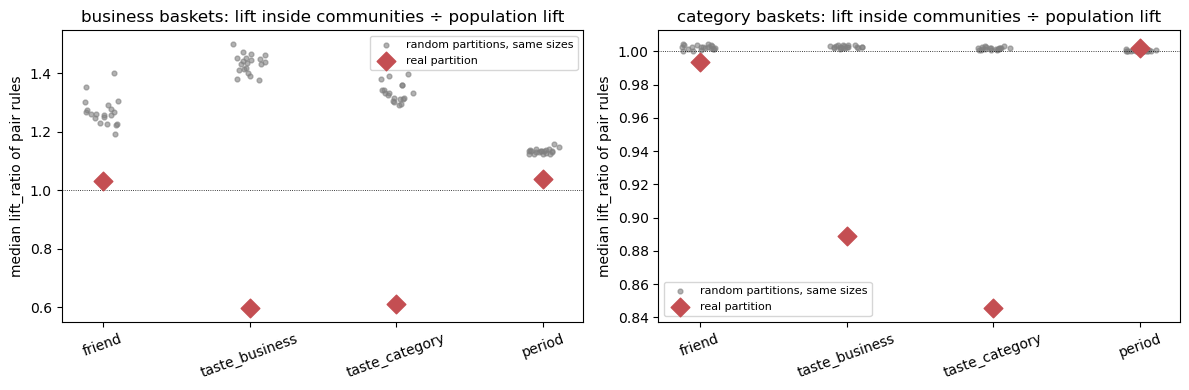

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, v in zip(axes, VERSIONS):
    for k, s in enumerate(order):
        g = NULL[(NULL.basket_type == v) & (NULL.community_system == s)]["median_lift_ratio"]
        real = REAL[(REAL.basket_type == v) & (REAL.community_system == s)]["median_lift_ratio"].iloc[0]
        ax.scatter(np.full(len(g), k) + np.random.default_rng(k).uniform(-.12, .12, len(g)), g, s=12, color="grey", alpha=.6,
                   label="random partitions, same sizes" if k == 0 else None)
        ax.scatter([k], [real], s=90, marker="D", color="#c44e52", label="real partition" if k == 0 else None, zorder=3)
    ax.axhline(1, color="black", lw=.6, ls=":")
    ax.set(xticks=range(len(order)), xticklabels=order, ylabel="median lift_ratio of pair rules",
           title=f"{v} baskets: lift inside communities ÷ population lift")
    ax.tick_params(axis="x", rotation=20); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIGURES / "04_lift_ratio_vs_null.png", dpi=150); plt.show()

In [20]:
# rules shared by several friend communities, and specific friend rules that are also period rules
for v in VERSIONS:
    pr = R.pair_rules(RULES["friend", v])
    if v == "category":
        pr = pr[pr.same_business_share < TAG_SHARE_MAX]
    k = R.rule_keys(pr)
    n_comm = k.groupby(k).transform("size")
    shared = readable(pr[n_comm >= 3], v).groupby("rule").agg(communities=("community_id", "nunique"),
                                                             lift_min=("lift", "min"), lift_max=("lift", "max"))
    print(f"{v}: {len(set(k))} distinct friend pair rules; {int((k.value_counts() >= 3).sum())} appear in >= 3 friend communities")
    display(shared.sort_values(["communities", "lift_max"], ascending=False).head(5).round(2))

business: 2081 distinct friend pair rules; 71 appear in >= 3 friend communities


,communities,lift_min,lift_max
rule,,,
Talula's Garden → Zahav,5,2.59,4.05
Amada → Zahav,5,2.15,3.51
Vernick Food & Drink → Zahav,4,2.92,6.09
Abe Fisher → Zahav,4,3.38,5.06
Philadelphia Museum of Art → Reading Terminal Market,4,1.60,3.95


category: 2893 distinct friend pair rules; 1651 appear in >= 3 friend communities


,communities,lift_min,lift_max
rule,,,
Vegetarian → Vegan,7,1.40,2.02
French → Wine Bars,7,1.51,1.97
Middle Eastern → Mediterranean,7,1.34,1.85
Thai → Asian Fusion,7,1.27,1.81
Ethnic Food → Middle Eastern,7,1.42,1.80


In [21]:
# period composition of the eligible friend communities (confounder)
elig_f = comm[(comm.community_system == "friend") & comm.eligible & (comm.basket_type == "business")].community_id
mix = pd.crosstab(friend.reindex(taste_c.index), taste_c["period"], normalize="index").loc[elig_f]
display((mix * 100).round(0).astype(int).add_suffix(" %"))

period,2011-13 %,2014-16 %,<=2010 %,>=2017 %
friend_community,,,,
0,4,24,0,72
1,30,13,52,5
2,48,42,3,7
3,18,37,4,41
4,23,32,12,32
5,28,46,5,20
6,20,51,3,25


> **What we found** (pair rules; z = (real − null mean) / null sd over 20 random partitions with the same sizes).
>
> **1. Taste communities absorb associations, as expected by construction.**
> - Inside taste communities, 95–98% of restaurant pair rules have a **lower** lift than in the population (median `lift_ratio` ≈ 0.6). Random partitions give 7–11% (median ≈ 1.3–1.4).
> - For categories the figures are 86–95% vs. ≈ 47%.
> - This is the circularity of section 1: the communities were built from these sets. It is the **reference** for how far a partition that tracks taste can go.
>
> **2. Friend communities absorb restaurant associations partially, and the period of activity does the same.**
> - Restaurants: 44.5% of friend pair rules have a lower lift inside the community, against 11% for random partitions (z ≈ 21). That is far from taste (95%) but well above chance.
> - The 4 **period bins alone** reach the same level: 44% (z ≈ 28).
> - Friend-specific restaurant rules overlap with **period-specific** rules about 4× more than chance (Jaccard 0.021 vs. 0.006, z ≈ 6). With taste-specific rules they overlap *less* than chance: 0 vs. 0.007 for restaurant-taste, 0.004 vs. 0.010 for category-taste.
> - The friend communities are themselves period-skewed. Friend community #0 is 72% ≥ 2017 users and #1 is 52% ≤ 2010.
> - **Interpretation:** much of what friend communities share at restaurant level is consistent with being active in the same years, when the same restaurants were open and popular. It is not evidence of shared taste. We did **not** control for period inside communities, so this is a strong confounder signal, not a decomposition.
>
> **3. Categories are not period-sensitive, and friend communities show only a weak taste signal there.**
> - For category rules the period partition is practically indistinguishable from random: 47.5% vs. 48.7% of rules below population lift, median `lift_ratio` 1.002 vs. 1.001. That supports the hypothesis that categories are insensitive to openings and closures.
> - Friend communities are still slightly above chance on categories: 55.6% vs. 46.5% (z ≈ 4.8), median `lift_ratio` 0.993 vs. 1.002. Taste communities reach 86–95%.
> - So friend communities carry a **small** category-level taste signal that the period does not explain. It is an order of magnitude weaker than the taste reference.
>
> **4. Rule sets: friend communities share most category rules.**
> - The average Jaccard between two friend communities' category rule sets is 0.43. Random partitions reach 0.80, taste communities 0.18–0.26.
> - 1,651 of 2,893 distinct friend category pair rules appear in ≥ 3 of the 7 friend communities, and the top ones (*Vegetarian → Vegan*, *French → Wine Bars*) in all 7.
> - Friend communities therefore have *somewhat* more distinct rules than chance, but far less than taste communities.
> - For restaurants all real partitions are more distinct than random (Jaccard 0.03 friend, 0.06 period, ≤ 0.02 taste, vs. ≈ 0.1–0.2 for random).
>
> **5. "Community-specific" counts must be read against the null.**
> - Random partitions produce *more* rules with `lift_ratio ≥ 1.5` than the real friend partition: 467 vs. 151 for restaurants.
> - In small random groups, the rules that pass the support threshold are the ones whose co-occurrence is high **by chance**. Their lift is inflated by sampling noise (winner's curse), and that inflates the specific-rule count.
> - The count of specific rules on its own is therefore **not** evidence that a community has its own taste. The lift-ratio distribution and the overlap with period and taste are more reliable.
> - For categories, friend communities have **no** specific pair rule at all.

## 4.6 Robustness over the 20 Louvain seeds

Steps 2 and 3 saved all 20 Louvain partitions. Friend stability was ARI 0.54; taste stability was 0.32–0.39. For every seed we rerun the pair-level measures of 4.5 (`MAX_K = 2`, which gives exactly the same pair rules) and the Jaccard between that seed's specific rules and the chosen partition's. Communities are matched **by rule content, never by label**.

In [22]:
SEED_FILES = {"friend": (PROC / "philadelphia_pa_friend_communities_all_seeds.parquet", 9),
              "taste_business": (RESULTS / "taste_communities_all_seeds_business.parquet", None),
              "taste_category": (RESULTS / "taste_communities_all_seeds_category.parquet", None)}
taste_summary = json.loads((RESULTS / "taste_summary.json").read_text())
ROB = []
t0 = time.perf_counter()
for s, (path, chosen) in SEED_FILES.items():
    seeds = pd.read_parquet(path).set_index("user_id")
    if chosen is None:
        chosen = int(taste_summary["communities"][s.replace("taste_", "")]["best seed"])
    for v in VERSIONS:
        tag_cut = TAG_SHARE_MAX if v == "category" else None
        ref = R.union(R.rule_sets(R.pair_rules(RULES[s, v]), specific_only=True, exclude_tag=tag_cut))
        for col in seeds.columns:
            _, r = R.mine_partition(BASKETS[v], seeds[col], params(v, max_k=2), POP[v], BIZ_INDEX if v == "category" else None)
            m = R.partition_measures(r, tag_cut, {"chosen": ref})
            ROB.append({"community_system": s, "basket_type": v, "seed": int(col.split("_")[1]),
                        "is_chosen": int(col.split("_")[1]) == chosen, **m})
ROB = pd.DataFrame(ROB)
print(f"{len(ROB)} partitions mined in {time.perf_counter() - t0:.0f} s")
rob = (ROB[~ROB.is_chosen].groupby(["community_system", "basket_type"])
       [["median_lift_ratio", "share_lift_ratio_lt1", "rules_specific", "jaccard_vs_chosen"]]
       .agg(["mean", "min", "max"]).round(3))
display(rob)

120 partitions mined in 50 s


median_lift_ratio                \
                                          mean    min    max   
community_system basket_type                                   
friend           business                1.035  0.986  1.114   
                 category                0.992  0.985  1.002   
taste_business   business                0.602  0.568  0.633   
                 category                0.891  0.871  0.910   
taste_category   business                0.628  0.564  0.700   
                 category                0.842  0.814  0.863   

                             share_lift_ratio_lt1                \
                                             mean    min    max   
community_system basket_type                                      
friend           business                   0.444  0.328  0.526   
                 category                   0.572  0.482  0.640   
taste_business   business                   0.911  0.863  0.960   
                 category                   0.865  0.834  0.898   
taste_category   business                   0.958  0.903  0.990   
                 category                   0.953  0.933  0.970   

                             rules_specific            jaccard_vs_chosen  \
                                       mean  min   max              mean   
community_system basket_type                                               
friend           business           330.737  126   629             0.165   
                 category             0.526    0     4             0.000   
taste_business   business           409.684  176  1115             0.131   
                 category             5.000    1    16             0.022   
taste_category   business           127.421   15   281             0.201   
                 category             1.368    0     4             0.158   

                                            
                                min    max  
community_system basket_type                
friend           business     0.042  0.307  
                 category     0.000  0.000  
taste_business   business     0.055  0.224  
                 category     0.000  0.154  
taste_category   business     0.027  0.441  
                 category     0.000  1.000

> **What we found.**
> - **Partition-level measures are stable across seeds.** For restaurants, friend median `lift_ratio` is 0.99–1.11 over the other 19 seeds, against 0.57–0.70 for taste. The share of rules below population lift is 33–53% for friends and 86–99% for taste. The conclusions of 4.5 therefore do not depend on the chosen run.
> - **Individual specific rules are not stable.** The Jaccard between a seed's specific rules and the chosen partition's averages 0.13–0.20 for restaurants, and is mostly 0 for categories, where almost no specific rules exist.
> - We therefore report measures of the whole distribution, not lists of "the" rules of a community.
> - **Not covered:** the null model was run for the chosen partitions only, not for every seed.

## 4.7 Saved outputs

| File | One row per | Content |
|---|---|---|
| `data/results/step4_basket_summary.parquet` | basket type | users, exclusions, items, basket sizes |
| `data/results/step4_frequent_itemsets.parquet` | itemset (full population) | `basket_type`, `itemset_ids`, `itemset_names`, `size`, `support_count`, `support` |
| `data/results/step4_rules.parquet` | rule × community | `community_system`, `basket_type`, `community_id`, `antecedent_ids/names`, `consequent_ids/names`, `support_count`, `support`, `confidence`, `lift`, `confidence_pop`, `lift_pop`, `lift_ratio`, `specific`, `same_business_share`, `same_business_tag` |
| `data/results/step4_community_metrics.parquet` | community | sizes, threshold (fraction + count), itemsets by size, rule counts, eligibility + reason |
| `data/results/step4_benchmark.parquet` | algorithm × collection | runtime per pass (median), peak memory |
| `data/results/step4_candidates.parquet` | collection | candidate-pair counts and structure sizes |
| `data/results/step4_bucket_sweep.parquet` | bucket count | PCY filtering vs. memory |
| `data/results/step4_comparison.parquet`, `step4_null.parquet` | measure / shuffle | 4.5 real vs. null |
| `data/results/step4_seed_robustness.parquet` | seed | 4.6 |
| `data/results/step4_summary.json` | — | parameters, environment, headline numbers |

In [23]:
def ids_names(t, v):
    return [str(BASKETS[v].item_ids[i]) for i in t], [str(NAMES[v][i]) for i in t]

def export_rules(r, v):
    a = [ids_names(t, v) for t in r.antecedent]; c = [ids_names(t, v) for t in r.consequent]
    out = r.drop(columns=["antecedent", "consequent"]).assign(
        antecedent_ids=[x[0] for x in a], antecedent_names=[x[1] for x in a],
        consequent_ids=[x[0] for x in c], consequent_names=[x[1] for x in c], basket_type=v)
    if "same_business_share" in out:
        out = out.assign(same_business_tag=out.same_business_share >= TAG_SHARE_MAX)
    return out

rules_out = pd.concat([export_rules(r, v).assign(community_system=s, community_id=lambda d: d.community_id.astype(str))
                       for (s, v), r in RULES.items() if not r.empty], ignore_index=True)
itemsets_out = pd.concat([pd.DataFrame([{"basket_type": v, "itemset_ids": ids_names(k, v)[0], "itemset_names": ids_names(k, v)[1],
                                         "size": len(k), "support_count": c, "support": c / FULL[v].n_transactions,
                                         "min_count": FULL[v].min_count} for k, c in FULL[v].itemsets.items()]) for v in VERSIONS],
                         ignore_index=True)
CAND_OUT = CAND.drop(columns=["candidates_k", "itemsets_by_size"]).assign(
    itemsets_by_size=CAND.itemsets_by_size.map(json.dumps), candidates_k=CAND.candidates_k.map(json.dumps))
outputs = {"step4_basket_summary": basket_summary, "step4_frequent_itemsets": itemsets_out, "step4_rules": rules_out,
           "step4_community_metrics": comm.assign(community_id=comm.community_id.astype(str)),
           "step4_benchmark": BENCH, "step4_candidates": CAND_OUT, "step4_bucket_sweep": SWEEP,
           "step4_comparison": pd.concat([CMP, J.drop(columns="other")], ignore_index=True), "step4_null": NULL,
           "step4_seed_robustness": ROB}
for name, df in outputs.items():
    df.to_parquet(RESULTS / f"{name}.parquet", index=False)
    print(f"{name}.parquet: {len(df):,} rows")

summary = {
    "params": {"seed": SEED, "positive": "is_positive (stars >= 3.5)", "generic_max_frac": GENERIC_MAX_FRAC,
               "max_cats_per_business": MAX_CATS_PER_BUSINESS, "min_businesses_per_category": MIN_BUSINESSES_PER_CATEGORY,
               "min_basket_items": MIN_BASKET_ITEMS, "min_support": MIN_SUPPORT, "min_confidence": MIN_CONFIDENCE,
               "min_lift": MIN_LIFT, "max_k": MAX_K, "min_count_rule": f"max(ceil(min_support * n), {MIN_COUNT_FLOOR})",
               "min_community_size": MIN_COMMUNITY_SIZE, "lift_ratio_min": LIFT_RATIO_MIN, "tag_share_max": TAG_SHARE_MAX,
               "n_shuffles": N_SHUFFLES, "n_buckets": N_BUCKETS, "timing_reps": TIMING_REPS,
               "comparison_rules": "pair rules (1 item -> 1 item)"},
    "environment": BM.environment(),
    "baskets": basket_summary.to_dict("records"),
    "full_population_itemsets": {v: FULL[v].by_size() for v in VERSIONS},
    "communities": excl.reset_index().to_dict("records"),
    "benchmark_population": BENCH[BENCH.collection == "population"][["basket_type", "algorithm", "total_s", "pass1_s", "pass2_pairs_s", "peak_mem_mb"]].to_dict("records"),
    "comparison_real_vs_null": CMP.round(4).to_dict("records"),
}
(RESULTS / "step4_summary.json").write_text(json.dumps(summary, indent=2, default=str))
print("step4_summary.json written")

step4_basket_summary.parquet: 2 rows
step4_frequent_itemsets.parquet: 11,917 rows


step4_rules.parquet: 1,859,393 rows
step4_community_metrics.parquet: 178 rows
step4_benchmark.parquet: 16 rows
step4_candidates.parquet: 8 rows
step4_bucket_sweep.parquet: 8 rows
step4_comparison.parquet: 80 rows
step4_null.parquet: 160 rows
step4_seed_robustness.parquet: 120 rows
step4_summary.json written


> **Summary of step 4**
> - **A-priori and PCY**, both written from scratch, return identical frequent itemsets on every collection. See 4.3 for the runtime, memory and candidate-pair trade-off.
> - **Taste communities** absorb the population's associations almost completely (95–98% of restaurant rules, 86–95% of category rules have lower lift inside the community). This is expected, because they were built from the same liked sets.
> - **Friend communities**, at restaurant level, absorb associations about as much as the activity-period bins do (44% vs. 44%). Their specific rules overlap with period rules, not with taste rules. At category level, where the period has no effect, friend communities show a weak but significant taste signal (56% vs. 47% for random).
>
> **Limitations**
> - **Period confounding** was diagnosed, not removed. Stratifying by period inside communities would be the next step.
> - **Community imbalance and heavy-reviewer communities** make rule counts uneven, which is why comparisons use pair rules.
> - **Results depend on the thresholds**: support 1% / 15%, confidence 0.25 / 0.5, lift-ratio cut-off 1.5. No support-threshold sensitivity sweep was run.
> - **The null model** shuffles labels over users. It keeps community sizes but not the basket-size mix, e.g. it does not reproduce heavy-reviewer communities.
> - **Rules describe co-occurrence of liked items, not causation.** Similar rules in friend communities do not show that friendship causes shared preferences.